# 1-board: rest-noise

Measure the noise of each raw channel with the bridge off, so later notebooks know how much of what they see in one sample is the chain and not the motor.

## Purpose

Every current, terminal and rail reading the firmware acts on is one ADC sample per control tick. The spread of those samples with nothing driving is the floor under every estimate built on them: the current limit's trip, the stall detector, the winding thermometer's ratio, the back-EMF read on a coasting terminal. This experiment measures that spread per channel at the control rate, at a 1S, a USB and a 2S supply level, and looks for structure in it, since a noise that repeats with the telemetry frame or at a line frequency is a coupling to fix rather than a floor to accept.

## Procedure

The board sits on the DPS with the bare load across its motor terminals, which draws nothing with the bridge off, and the adapter on its bus at 3 Mbps. `capture.py` powers the board, then at a rail of 3.7 V, 5.0 V and 7.4 V records three torque-off streams of three seconds, the longest burst the servo arms, the board NTC and the chip's 1.2 V reference in every row. Each stream is an `osc sweep` whose capture is its baseline; the 5 % rung of 50 ms that follows is the smallest the tool records and is left out of the analysis.

1. The board on the DPS, the bare load on the terminals, the adapter on the bus.
2. `capture.py`. It asks for the leads off the DPS before the output comes on, then on.

## Data

- `rest-<V>V-<k>/sweep.csv`, `meta.json`: one row per control tick. Segment 0 is the rest. `current_raw`, `vmotor_a`, `vmotor_b`, `vbus_raw`, `ntc_raw` and `vref_raw` are ADC counts, the last the chip's 1.2 V reference, which reads VDD; `tick` is the control tick, and a jump in it is a dropped frame.

### One stream

The first rest stream. Left, the first 20 ms of every raw channel, one sample per control tick, so the reading is seen toggling between neighbouring codes. Right, how often each code was read over the whole three seconds.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import b41t, boards, display, laps, results, tel
from oscnb.display import show

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
BOARD = boards.BOARDS[boards.DEFAULT]
CAPTURE = Path("../../../telemetry") / BOARD.key / "rest-noise" / "capture-1"
CAPTURE = CAPTURE.resolve()
print(BOARD.key, "from", results.rel(CAPTURE))

dev-v006-2A-D from telemetry/dev-v006-2A-D/rest-noise/capture-1


9 streams


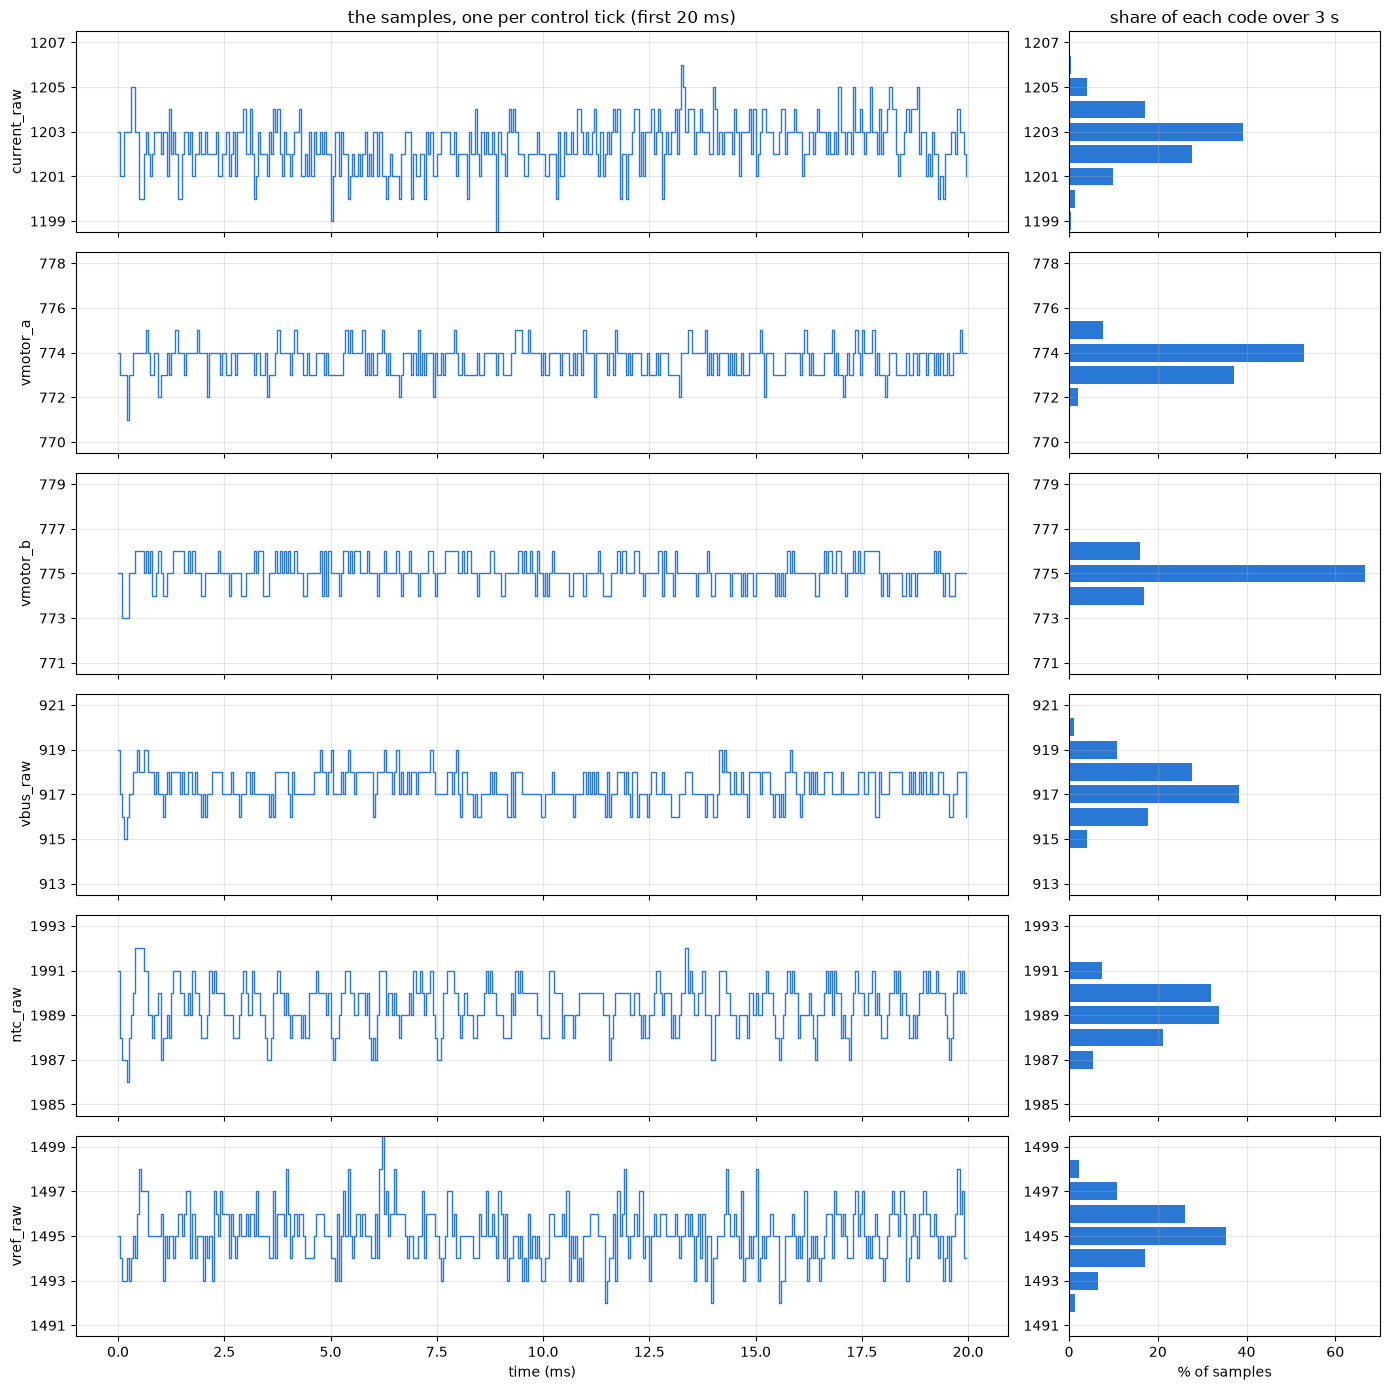

60000 rows over 3.0 s; gaps: none


In [2]:
folders = sorted(p for p in CAPTURE.glob("rest-*") if (p / "sweep.csv").exists())
print(len(folders), "streams")
df, meta = tel.load(folders[0], BOARD)
rest = df[df["seg"] == 0]
chans = ["current_raw", "vmotor_a", "vmotor_b", "vbus_raw", "ntc_raw", "vref_raw"]
win = rest.iloc[:400]
fig, ax = plt.subplots(len(chans), 2, figsize=(14, 14), sharex="col", gridspec_kw={"width_ratios": [3, 1]})
for (a, h), ch in zip(ax, chans):
    mid = round(rest[ch].mean())
    a.step(win["t"] * 1e3, win[ch], where="post", lw=1.0, color=BLUE); a.set_ylabel(ch); a.grid(alpha=0.3)
    codes = rest[ch].value_counts().sort_index()
    h.barh(codes.index, codes.values / len(rest) * 100, color=BLUE); h.grid(alpha=0.3)
    for x in (a, h):
        x.set_ylim(mid - 4.5, mid + 4.5); x.set_yticks(range(mid - 4, mid + 5, 2))
ax[0, 0].set_title("the samples, one per control tick (first 20 ms)"); ax[0, 1].set_title("share of each code over 3 s")
ax[-1, 0].set_xlabel("time (ms)"); ax[-1, 1].set_xlabel("% of samples")
plt.tight_layout(); plt.show()
print(f"{len(rest)} rows over {rest['t'].iloc[-1] - rest['t'].iloc[0]:.1f} s; gaps: {tel.gaps(rest).sum() or 'none'}")

Each channel at rest for three seconds, the longest burst the servo arms, three streams a level. The current channel sits on the amplifier's zero, the taps on the bias node, the rail on the supply.

## Method

The spread of each channel over the rest, as a standard deviation in counts, then in the units the chain converts to. Three streams per level give three values, and the spread between them says how stable the floor is. Two structures are checked: the mean of each channel by position in the 16-row telemetry frame, which shows a coupling from the bus, and the spectrum of the current channel, which shows a line or a switching frequency.

### Spread per channel

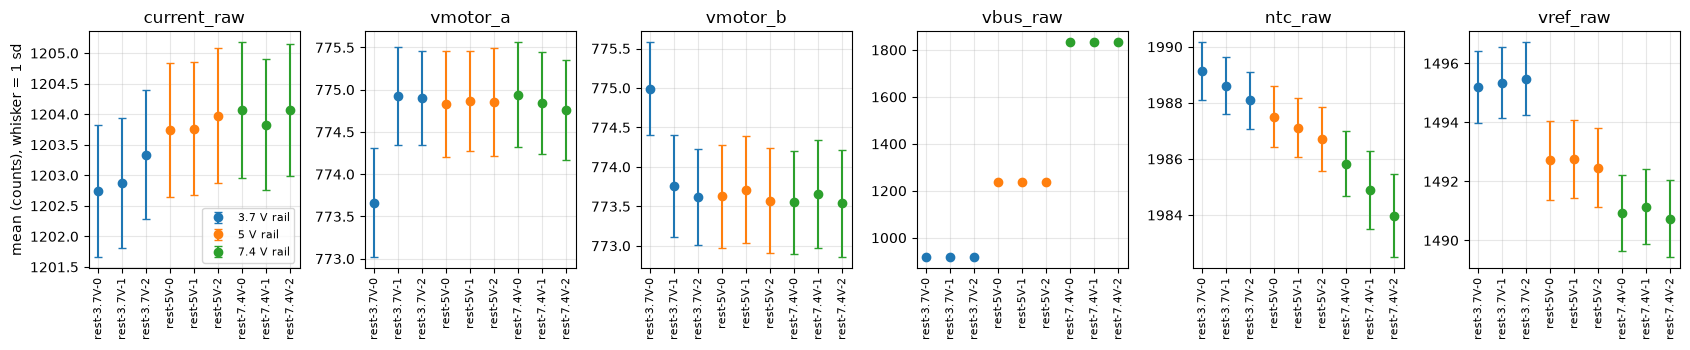

In [3]:
rows = []
for p in folders:
    df, meta = tel.load(p, BOARD)
    rest = df[df["seg"] == 0]
    volts = float(p.name.split("-")[1].rstrip("V"))
    row = {"stream": p.name, "volts": volts, "rows": len(rest), "missing": int(tel.gaps(df).sum())}
    for c in tel.RAW:
        if c in rest and rest[c].notna().any():
            row[c + "_mean"] = rest[c].mean(); row[c + "_sd"] = rest[c].std()
    rows.append(row)
spread = pd.DataFrame(rows)
fig, ax = plt.subplots(1, len(chans), figsize=(17, 3.6))
colors = {v: f"C{k}" for k, v in enumerate(sorted(spread["volts"].unique()))}
for a, ch in zip(ax, chans):
    for v, g in spread.groupby("volts"):
        a.errorbar(g["stream"], g[ch + "_mean"], yerr=g[ch + "_sd"], fmt="o", capsize=3, color=colors[v], label=f"{v:g} V rail")
    a.set_title(ch); a.tick_params(axis="x", rotation=90, labelsize=8); a.grid(alpha=0.3)
ax[0].set_ylabel("mean (counts), whisker = 1 sd"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Each channel's mean per stream, one point a stream, the whisker one standard deviation. The point says where the channel rests: the current channel on the amplifier's zero, the taps on the bias node, the NTC on the board's temperature, the rail on the level. Three points at a level on top of each other say the rest is repeatable, and a step between levels says the rest moves with the rail.

current_raw  1.08 counts rms, 1.0 mA
vmotor_a     0.61 counts rms, 2.4 mV at the terminal
vmotor_b     0.65 counts rms, 2.6 mV at the terminal
vbus_raw     1.26 counts rms, 5.1 mV on the rail
ntc_raw      1.15 counts rms
vref_raw     1.28 counts rms, 2.8 mV of VDD
VDD at a 3.7 V rail: 3.287 V (vref_raw 1495.3)
VDD at a 5 V rail: 3.293 V (vref_raw 1492.6)
VDD at a 7.4 V rail: 3.297 V (vref_raw 1490.9)


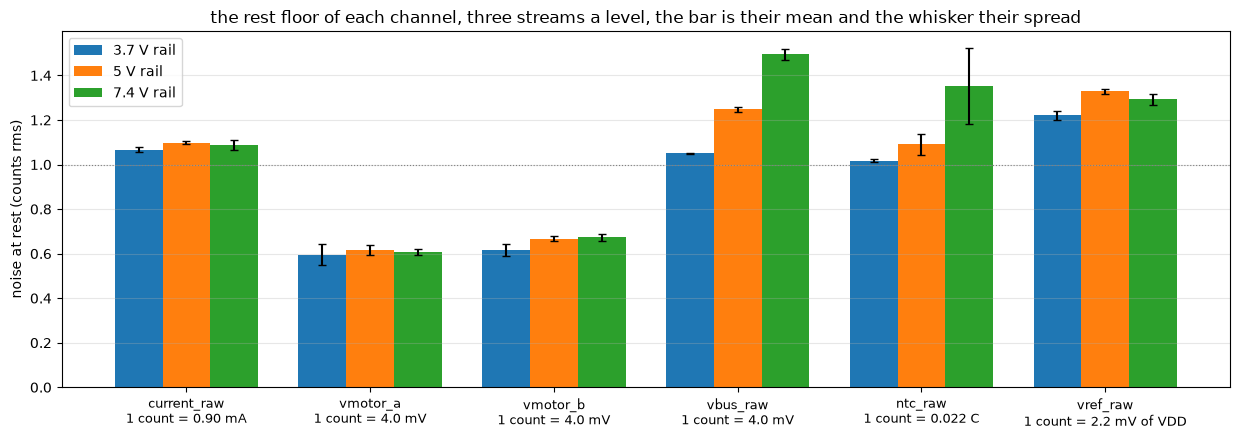

In [4]:
sd = spread.groupby("volts")[[c + "_sd" for c in chans]].agg(["mean", "std"])
vdd_per_count = (BOARD.vdd_v(1491) - BOARD.vdd_v(1492)) * 1e3     # mV of VDD per count of vref_raw near its reading
units = {"current_raw": ("mA", BOARD.a_per_count * 1e3), "vmotor_a": ("mV at the terminal", BOARD.v_term_per_count * 1e3),
         "vmotor_b": ("mV at the terminal", BOARD.v_term_per_count * 1e3), "vbus_raw": ("mV on the rail", BOARD.v_rail_per_count * 1e3)}
for c, (u, k) in units.items():
    s = spread[c + "_sd"].mean()
    print(f"{c:<12} {s:.2f} counts rms, {s * k:.1f} {u}")
print(f"ntc_raw      {spread['ntc_raw_sd'].mean():.2f} counts rms")
print(f"vref_raw     {spread['vref_raw_sd'].mean():.2f} counts rms, {spread['vref_raw_sd'].mean() * vdd_per_count:.1f} mV of VDD")
for v, g in spread.groupby("volts"):
    print(f"VDD at a {v:g} V rail: {BOARD.vdd_v(g['vref_raw_mean'].mean()):.3f} V (vref_raw {g['vref_raw_mean'].mean():.1f})")

val = lambda a: a() if callable(a) else a
unit = {"current_raw": f"1 count = {val(BOARD.a_per_count) * 1e3:.2f} mA",
        "vmotor_a": f"1 count = {val(BOARD.v_term_per_count) * 1e3:.1f} mV",
        "vmotor_b": f"1 count = {val(BOARD.v_term_per_count) * 1e3:.1f} mV",
        "vbus_raw": f"1 count = {val(BOARD.v_rail_per_count) * 1e3:.1f} mV",
        "ntc_raw": f"1 count = {abs(BOARD.ntc_c_beta(1956) - BOARD.ntc_c_beta(1955)):.3f} C",
        "vref_raw": f"1 count = {vdd_per_count:.1f} mV of VDD"}
fig, ax = plt.subplots(figsize=(12.5, 4.5))
levels = sd.index.to_list(); w = 0.26
for i, v in enumerate(levels):
    m = [sd.loc[v, (ch + "_sd", "mean")] for ch in chans]
    e = [sd.loc[v, (ch + "_sd", "std")] for ch in chans]
    ax.bar(np.arange(len(chans)) + (i - 1) * w, m, w, yerr=e, capsize=3, label=f"{v:g} V rail")
ax.axhline(1, color="gray", lw=0.8, ls=":")
ax.set_xticks(range(len(chans)), [f"{ch}\n{unit[ch]}" for ch in chans], fontsize=9)
ax.set_ylabel("noise at rest (counts rms)"); ax.set_title("the rest floor of each channel, three streams a level, the bar is their mean and the whisker their spread")
ax.legend(); ax.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.show()

The standard deviation per channel at each level, with its spread over the repeats, then each one in the unit its chain reads. The bars say the same thing in one picture: every channel sits near one count, and only the rail's floor moves with the level.

### Structure

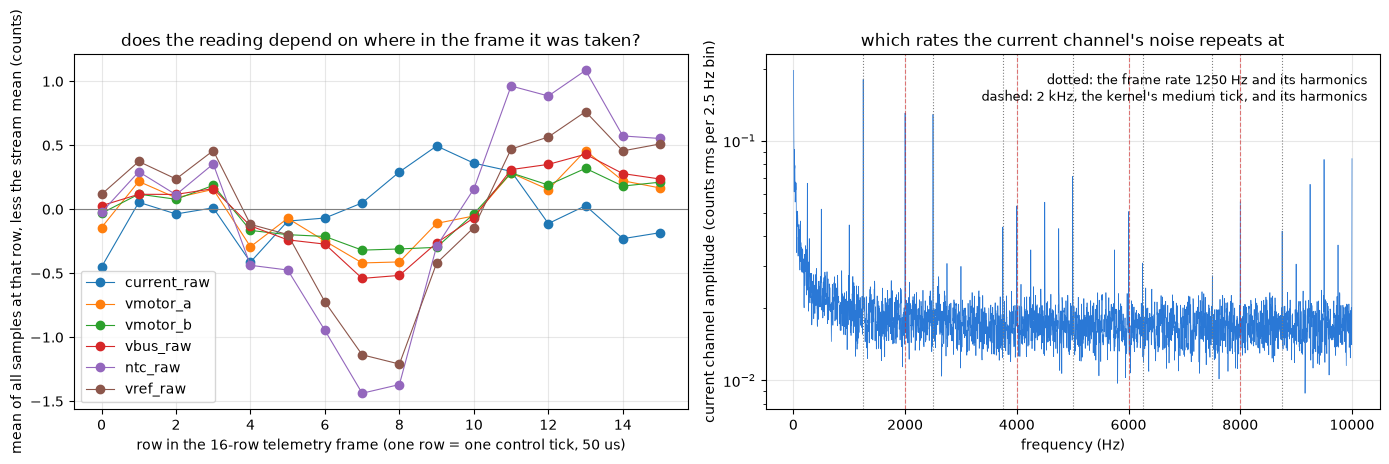

frame-position spread of the current channel 0.95 counts; strongest line over 100 Hz at 1250 Hz


In [5]:
df, meta = tel.load(folders[0], BOARD)
rest = df[df["seg"] == 0]
chans = ["current_raw", "vmotor_a", "vmotor_b", "vbus_raw", "ntc_raw", "vref_raw"]
by = rest.groupby(rest["tick"] % 16)[chans].mean()
fs = meta.get("tick_hz", 20000)
frame_hz = fs / 16
x = rest["current_raw"].to_numpy(float) - rest["current_raw"].mean()
from scipy.signal import welch
f, pwr = welch(x, fs, nperseg=8000, scaling="spectrum"); amp = np.sqrt(pwr)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
(by - by.mean()).plot(ax=ax[0], marker="o", lw=0.8)
ax[0].axhline(0, color="gray", lw=0.8)
ax[0].set_xlabel("row in the 16-row telemetry frame (one row = one control tick, 50 us)")
ax[0].set_ylabel("mean of all samples at that row, less the stream mean (counts)")
ax[0].set_title("does the reading depend on where in the frame it was taken?"); ax[0].grid(alpha=0.3)
ax[1].semilogy(f[1:], amp[1:], lw=0.5, color=BLUE)
for k in range(1, 8):
    ax[1].axvline(k * frame_hz, color="gray", lw=0.8, ls=":")
for k in range(1, 5):
    ax[1].axvline(k * 2000, color="C3", lw=0.8, ls="--", alpha=0.6)
ax[1].text(0.98, 0.95, f"dotted: the frame rate {frame_hz:.0f} Hz and its harmonics\ndashed: 2 kHz, the kernel's medium tick, and its harmonics", transform=ax[1].transAxes, ha="right", va="top", fontsize=9)
ax[1].set_xlabel("frequency (Hz)"); ax[1].set_ylabel("current channel amplitude (counts rms per 2.5 Hz bin)")
ax[1].set_title("which rates the current channel's noise repeats at"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
peak = f[f > 100][np.argmax(amp[f > 100])]
print(f"frame-position spread of the current channel {by['current_raw'].max() - by['current_raw'].min():.2f} counts; strongest line over 100 Hz at {peak:.0f} Hz")

Left, the telemetry goes out in frames of sixteen rows, one row per control tick. Every sample taken at the same row of a frame is averaged over the 3750 frames of the stream, and the stream mean is taken off. A flat line at zero would say nothing in the frame touches the reading. A shape says a disturbance repeats once a frame. Right, the current channel as a spectrum. Random noise is a flat floor, and a disturbance that repeats at one rate stands up as a line at that rate. The dotted lines mark the frame rate and its harmonics.

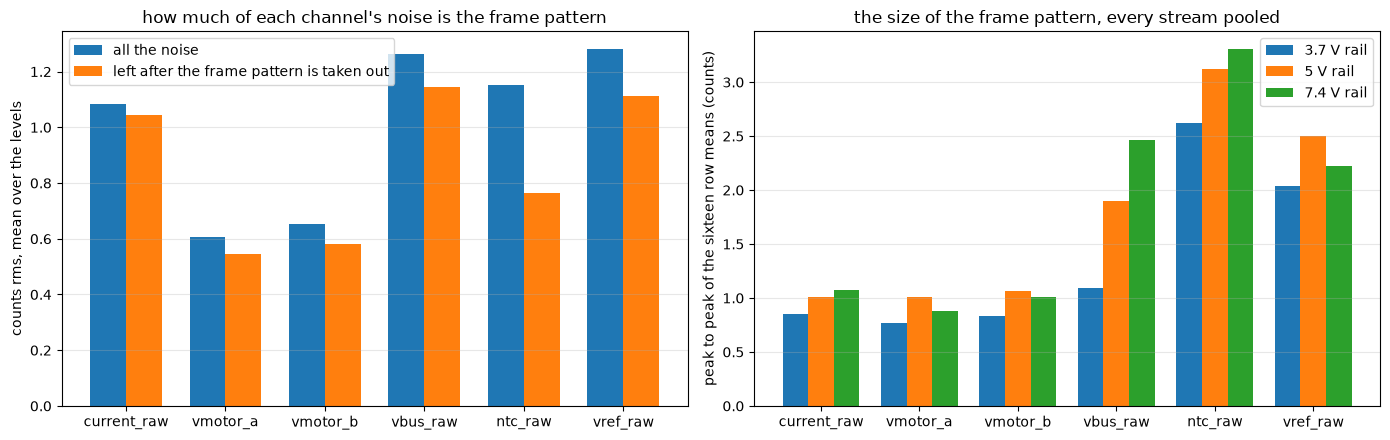

In [6]:
pat = []
for folder in folders:
    frame, _ = tel.load(folder, BOARD)
    at_rest = frame[frame["seg"] == 0]
    row = at_rest["tick"] % 16
    for ch in chans:
        v = at_rest[ch].astype(float)
        means = v.groupby(row).mean()
        pat.append({"volts": float(folder.name.split("-")[1][:-1]), "channel": ch, "sd": v.std(),
                    "pattern_pp": means.max() - means.min(), "residual_sd": (v - v.groupby(row).transform("mean")).std()})
pat = pd.DataFrame(pat).groupby(["channel", "volts"])[["sd", "pattern_pp", "residual_sd"]].mean()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(chans)); w = 0.26
over = pat.groupby("channel").mean().loc[chans]
ax[0].bar(x - 0.18, over["sd"], 0.36, label="all the noise")
ax[0].bar(x + 0.18, over["residual_sd"], 0.36, label="left after the frame pattern is taken out")
ax[0].set_xticks(x, chans); ax[0].set_ylabel("counts rms, mean over the levels"); ax[0].legend(); ax[0].grid(alpha=0.3, axis="y")
ax[0].set_title("how much of each channel's noise is the frame pattern")
for i, v in enumerate(sorted(pat.index.get_level_values("volts").unique())):
    ax[1].bar(x + (i - 1) * w, [pat.loc[(ch, v), "pattern_pp"] for ch in chans], w, label=f"{v:g} V rail")
ax[1].set_xticks(x, chans); ax[1].set_ylabel("peak to peak of the sixteen row means (counts)"); ax[1].legend(); ax[1].grid(alpha=0.3, axis="y")
ax[1].set_title("the size of the frame pattern, every stream pooled")
plt.tight_layout(); plt.show()

The frame pattern over every stream. Left, each channel's noise as it is, beside what is left once each row's mean is taken out of its samples. The gap between the two bars is the pattern's share. Right, the pattern's size at each level, as the peak to peak of the sixteen row means.

## Results

Every channel sits at the ADC's quantization. The taps toggle between two neighbouring codes, the current channel spreads over about three, the rail over four at 7.4 V. In units, the current channel's floor is 1.1 counts rms, about 1 mA. The taps are 0.7 counts, 3 mV at the terminal. The rail is 1.0 to 1.5 counts, 4 to 6 mV, and grows with the level while the taps and the current channel do not. The NTC is 1.1 counts, a few hundredths of a degree. The chip's 1.2 V reference is 1.3 counts, 2.8 mV of VDD. The rests repeat: the three streams at a level sit on top of each other on every channel, apart from the first stream of the run, whose tap A sat a count under the others. The current channel's zero rises by one count from the 3.7 V rail to the 7.4 V rail, and the NTC climbs two counts over the run, a few hundredths of a degree, as the board warms on the higher rail. The reference reads 1491 counts on the 7.4 V rail, 1493 at 5.0 V and 1495 at 3.7 V, which is VDD at 3.297 V, 3.293 V and 3.287 V: the regulator holds within 10 mV over the three rails, and the 10 mV it gives up on the 1S rail is most likely its load regulation as its headroom shrinks.

There is structure, and it is the telemetry frame. Each channel's mean by row in the frame wanders by about one count peak to peak on the current channel and the taps, two to three counts on the rail at 7.4 V and three counts on the NTC. The taps, the rail, the NTC and the reference follow one shape, low around rows 7 and 8 and high around rows 12 to 14, the reference at about 2 counts peak to peak. The current channel's spectrum has its lines at 1250 Hz, which is the frame rate at 20 kHz over 16 rows, and at its harmonics, with a second, smaller family at 2 kHz and its harmonics, which is the rate of the kernel's medium tick. Taking the row means out leaves the current channel at 1.0 counts rms, the taps at 0.6, the NTC at 0.8 and the reference at 1.1, so the pattern is a small part of the current channel's floor and the largest part of the NTC's.

The result file carries the floor per channel in counts rms, with the spread over the repeats as the bounds, and the frame-position spread of the current channel.

In [7]:
def q(c):
    s = spread[c + "_sd"]
    return results.quantity(s.mean(), lo=s.min(), hi=s.max(), unit="counts rms")
results.write("1-board", "rest-noise", CAPTURE, pair=BOARD.key,
              notes="torque-off streams at the control rate, bridge off, bare load on the terminals",
              current_noise=q("current_raw"), tap_a_noise=q("vmotor_a"), tap_b_noise=q("vmotor_b"), rail_noise=q("vbus_raw"),
              ntc_noise=q("ntc_raw"), vref_noise=q("vref_raw"),
              vdd_v=results.quantity(float(BOARD.vdd_v(spread["vref_raw_mean"].mean())), lo=float(BOARD.vdd_v(spread["vref_raw_mean"].max())), hi=float(BOARD.vdd_v(spread["vref_raw_mean"].min())), unit="V"),
              current_frame_spread=results.quantity(by["current_raw"].max() - by["current_raw"].min(), unit="counts"))

PosixPath('stages/1-board/rest-noise/results/dev-v006-2A-D.json')

## Limitations

- The bridge is off, so this is the chain's floor with no switching. The floor under drive, with the bridge chopping and the current climbing inside every window, is a different number and comes from the sample-timing experiment's ladders.
- Three seconds at 20 kHz resolves nothing under a hertz. A slow wander of the zero shows in the laps of current-scale as a difference between their rests.
- The streams are themselves the telemetry, so the frame pattern is measured with the bus busy. Between bursts the bus is quiet and the kernel runs the same, so the floor the firmware sees then may be the residual without the pattern. This capture cannot say.
- The DPS is the supply. A pack's floor may differ by its own impedance, and USB power by its ripple.

## Open questions

- Where the frame pattern couples in. The taps, the rail, the NTC and the chip's own 1.2 V reference share its shape, and the reference has no input on the board at all, which points at something inside the chip during the frame's transmit, the ADC's reference or its ground, rather than at any one input. A stream with a shorter row, or a frame of a different length, would say whether the shape follows the transmit.
- How much of the current channel's share of the pattern is board D's bodge. Its op-amp pull-ups reach 3V3 by two flying wires next to the amplifier's bias, and the current channel's frame shape is its own, peaking at row 9 where the taps, the rail and the NTC peak at rows 12 to 14. The rev 2B board has the pull-ups on the copper. The same streams on the first 2B board, and this spectrum beside that one, would say whether the current channel's lines shrink to the others' size.
- Whether the floor changes with the load on the terminals. The same streams with the terminals open would say what the load's lead loop picks up.

## Conclusion

The board's chain at rest is as quiet as the ADC lets it be. Every raw channel sits within about one count rms of its mean, which is a milliamp on the current channel, three millivolts on a terminal and a few millivolts on the rail. Nothing in the later stages has to allow for a floor above that from the chain itself. The floors under drive come from the sample-timing ladders.

The one structure is the telemetry frame, a pattern of about one count peak to peak locked to the 1250 Hz frame rate and shared by the taps, the rail, the NTC and the chip's own reference. It is a coupling and not a floor, but at a count it is under anything the firmware acts on, so it is recorded here and left alone. It matters to a reader who averages a channel over fewer than sixteen rows and expects the mean to be quiet to a tenth of a count.

Later experiments should take two things from this run.

- A single sample on any raw channel is good to about a count. An average over whole frames is good to a tenth, since whole frames average the pattern out.
- The rail's floor grows with the level, from one count at 3.7 V to one and a half at 7.4 V, while the taps and the current channel stay put. The most likely source is the supply's own ripple through the rail tap, and the terminal-chain experiment should expect it.
- VDD on this board is 3.29 V, read from the chip's own reference, and holds within 10 mV from a 3.7 V rail to a 7.4 V one. The 3V3 pass of terminal-chain takes it down to a 3.3 V rail, where the regulator runs out of headroom.